<a href="https://colab.research.google.com/github/sergeydorof/neural_networks_labs/blob/main/lab2/nn_lab2_preproc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv('drive/MyDrive/Volgograd_weather.csv', encoding='windows-1251', sep=';')

In [3]:
data

,LocalTime,T,P0,P,U,DD
0,15.10.2020 23:00,11.0,752.2,764.3,88.0,Ветер
1,15.10.2020 22:00,10.0,752.1,764.3,88.0,Ветер
2,15.10.2020 21:00,13.0,752.3,764.3,82.0,Ветер
3,15.10.2020 20:30,13.0,752.3,764.3,82.0,Ветер
4,15.10.2020 20:00,13.0,752.3,764.3,88.0,Ветер
...,...,...,...,...,...,...
117265,15.10.2012 04:00,7.0,756.5,768.9,71.0,Ветер
117266,15.10.2012 03:00,6.0,757.2,769.6,76.0,Ветер
117267,15.10.2012 02:00,5.0,757.1,769.6,81.0,Ветер
117268,15.10.2012 01:00,6.0,756.5,768.9,81.0,Ветер


Сделаю дату и время индексом

In [4]:
data['LocalTime'] = pd.to_datetime(data['LocalTime'], format='%d.%m.%Y %H:%M')
data = data.set_index('LocalTime')
data = data.sort_index()
data

,T,P0,P,U,DD
LocalTime,,,,,
2012-10-15 00:00:00,5.0,756.4,768.9,76.0,Ветер
2012-10-15 01:00:00,6.0,756.5,768.9,81.0,Ветер
2012-10-15 02:00:00,5.0,757.1,769.6,81.0,Ветер
2012-10-15 03:00:00,6.0,757.2,769.6,76.0,Ветер
2012-10-15 04:00:00,7.0,756.5,768.9,71.0,Ветер
...,...,...,...,...,...
2020-10-15 20:00:00,13.0,752.3,764.3,88.0,Ветер
2020-10-15 20:30:00,13.0,752.3,764.3,82.0,Ветер
2020-10-15 21:00:00,13.0,752.3,764.3,82.0,Ветер


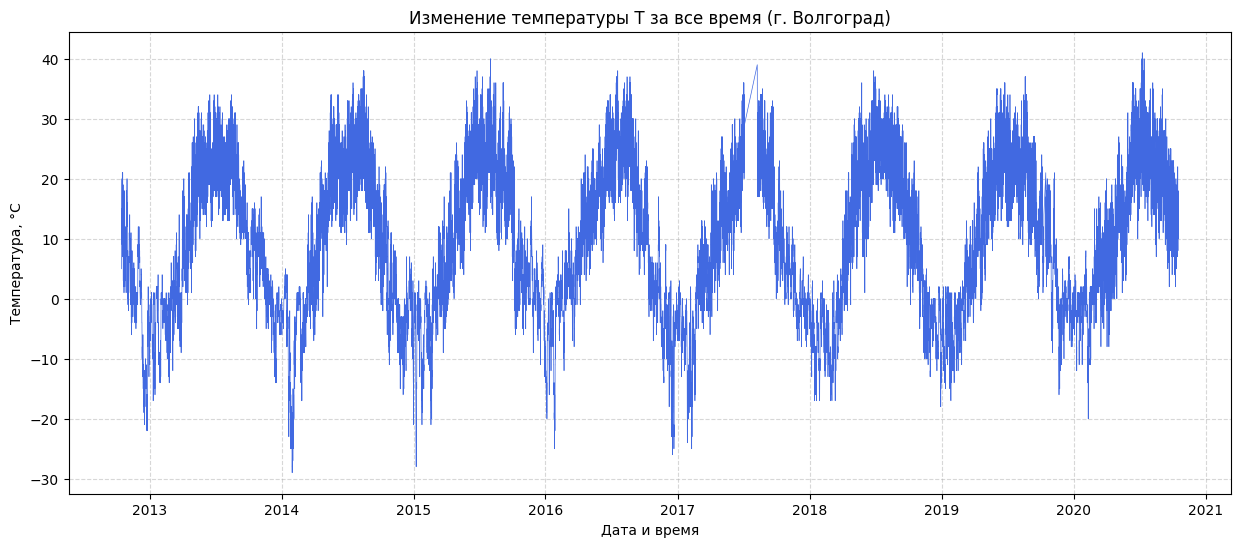

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.plot(data.index, data['T'], color='royalblue', linewidth=0.5)
plt.title('Изменение температуры T за все время (г. Волгоград)')
plt.xlabel('Дата и время')
plt.ylabel('Температура, °C')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Посмотрю температуру за год, допустим 2019 и посмотрю ветер

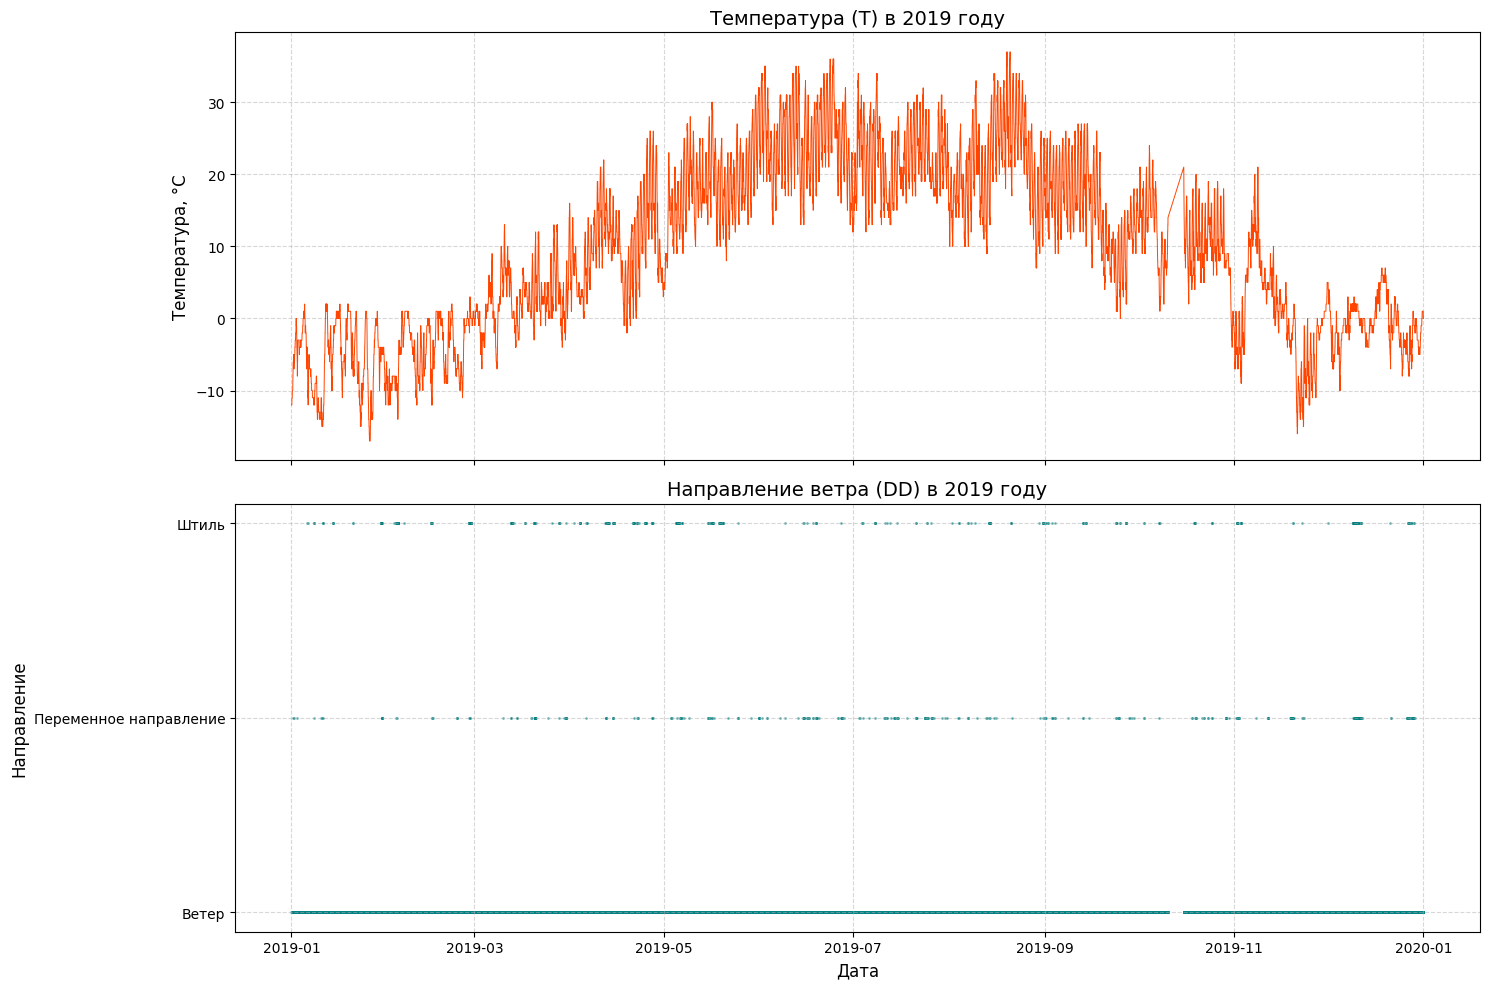

In [6]:
import matplotlib.pyplot as plt

data_2019 = data.loc['2019']

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

axes[0].plot(data_2019.index, data_2019['T'], color='orangered', linewidth=0.7)
axes[0].set_title('Температура (T) в 2019 году', fontsize=14)
axes[0].set_ylabel('Температура, °C', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(data_2019.index, data_2019['DD'], color='teal', s=1, alpha=0.5)
axes[1].set_title('Направление ветра (DD) в 2019 году', fontsize=14)
axes[1].set_xlabel('Дата', fontsize=12)
axes[1].set_ylabel('Направление', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

В Волгограде почти всегда ветер похоже

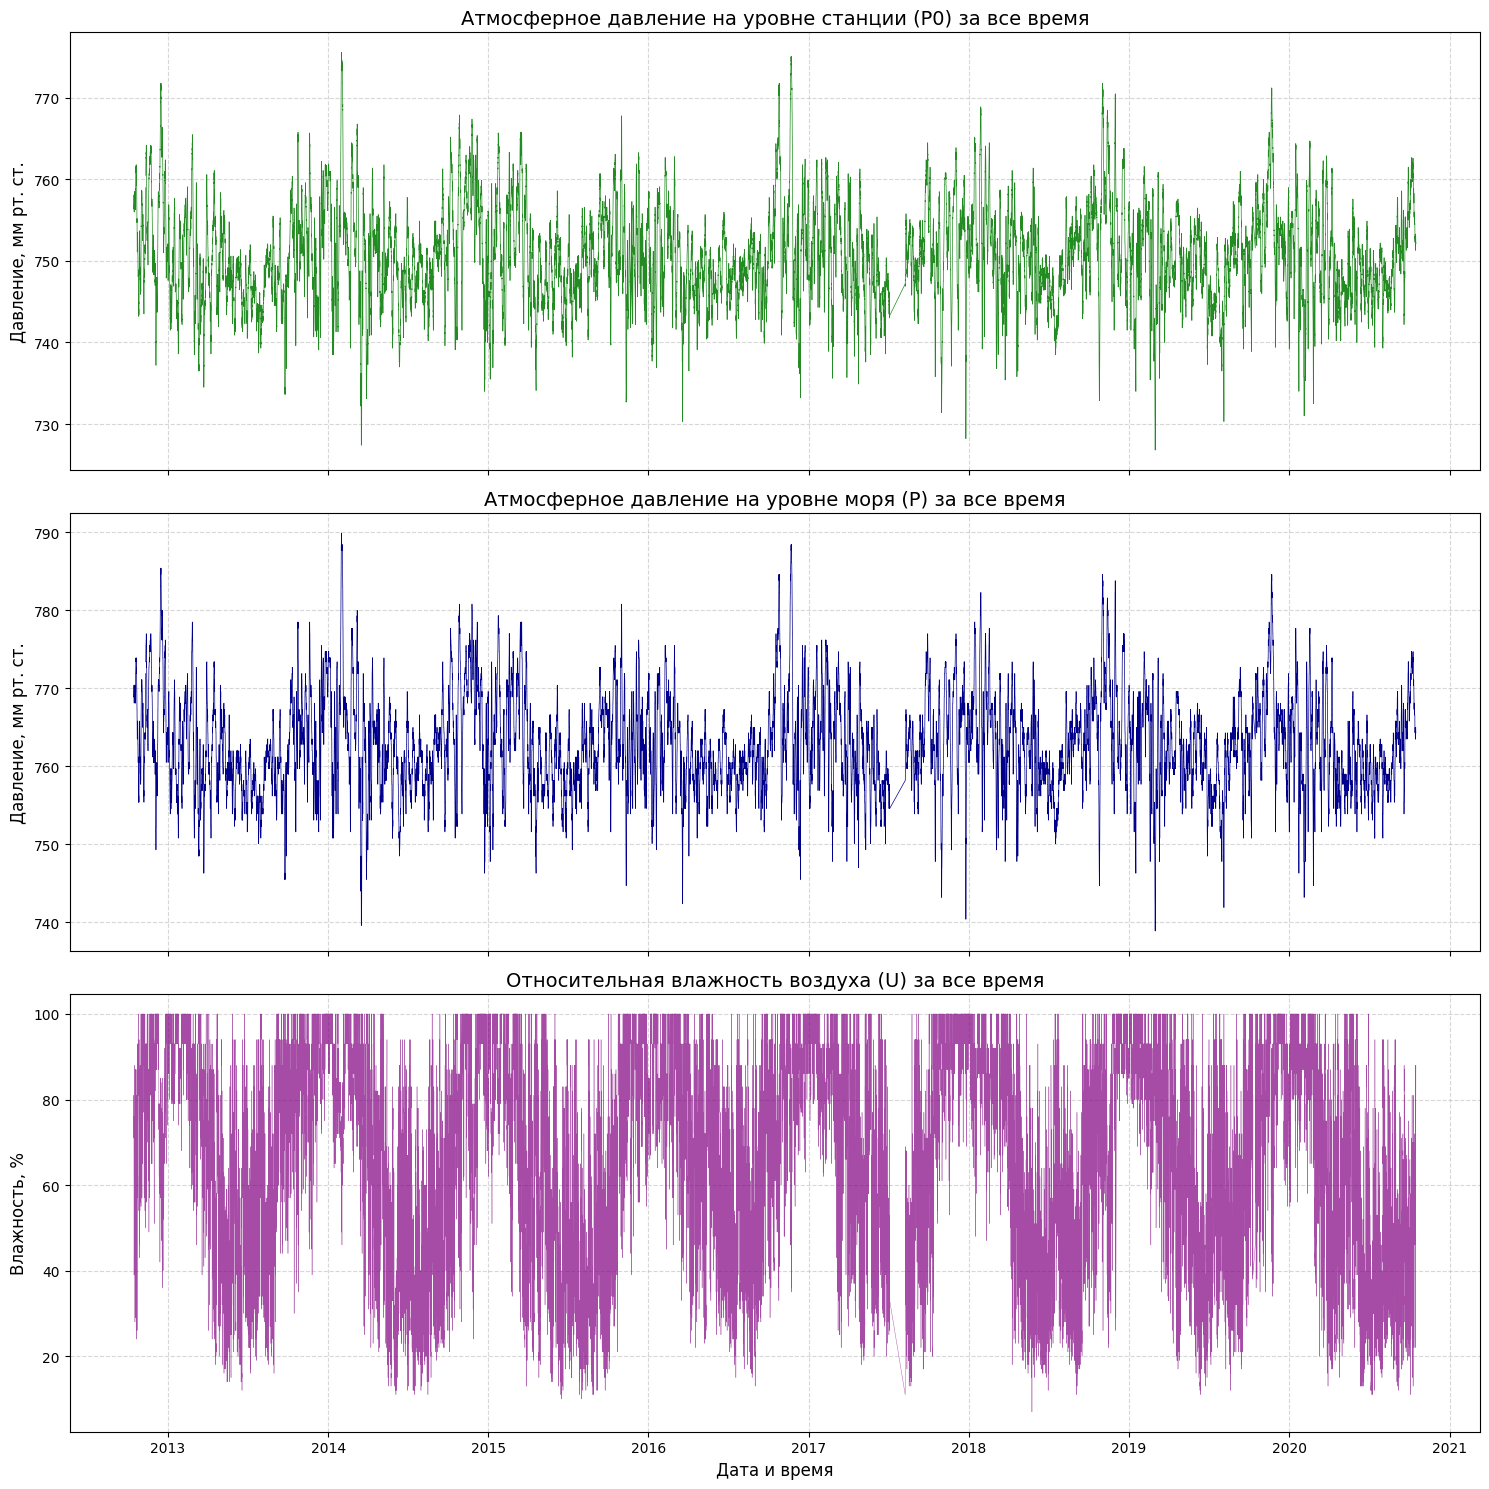

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(15, 15), sharex=True)

# График давления P0
axes[0].plot(data.index, data['P0'], color='forestgreen', linewidth=0.5)
axes[0].set_title('Атмосферное давление на уровне станции (P0) за все время', fontsize=14)
axes[0].set_ylabel('Давление, мм рт. ст.', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# График давления P
axes[1].plot(data.index, data['P'], color='darkblue', linewidth=0.5)
axes[1].set_title('Атмосферное давление на уровне моря (P) за все время', fontsize=14)
axes[1].set_ylabel('Давление, мм рт. ст.', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

# График влажности U
axes[2].plot(data.index, data['U'], color='purple', linewidth=0.3, alpha=0.7)
axes[2].set_title('Относительная влажность воздуха (U) за все время', fontsize=14)
axes[2].set_xlabel('Дата и время', fontsize=12)
axes[2].set_ylabel('Влажность, %', fontsize=12)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

2017 год чето странный посмотрю его отдельно

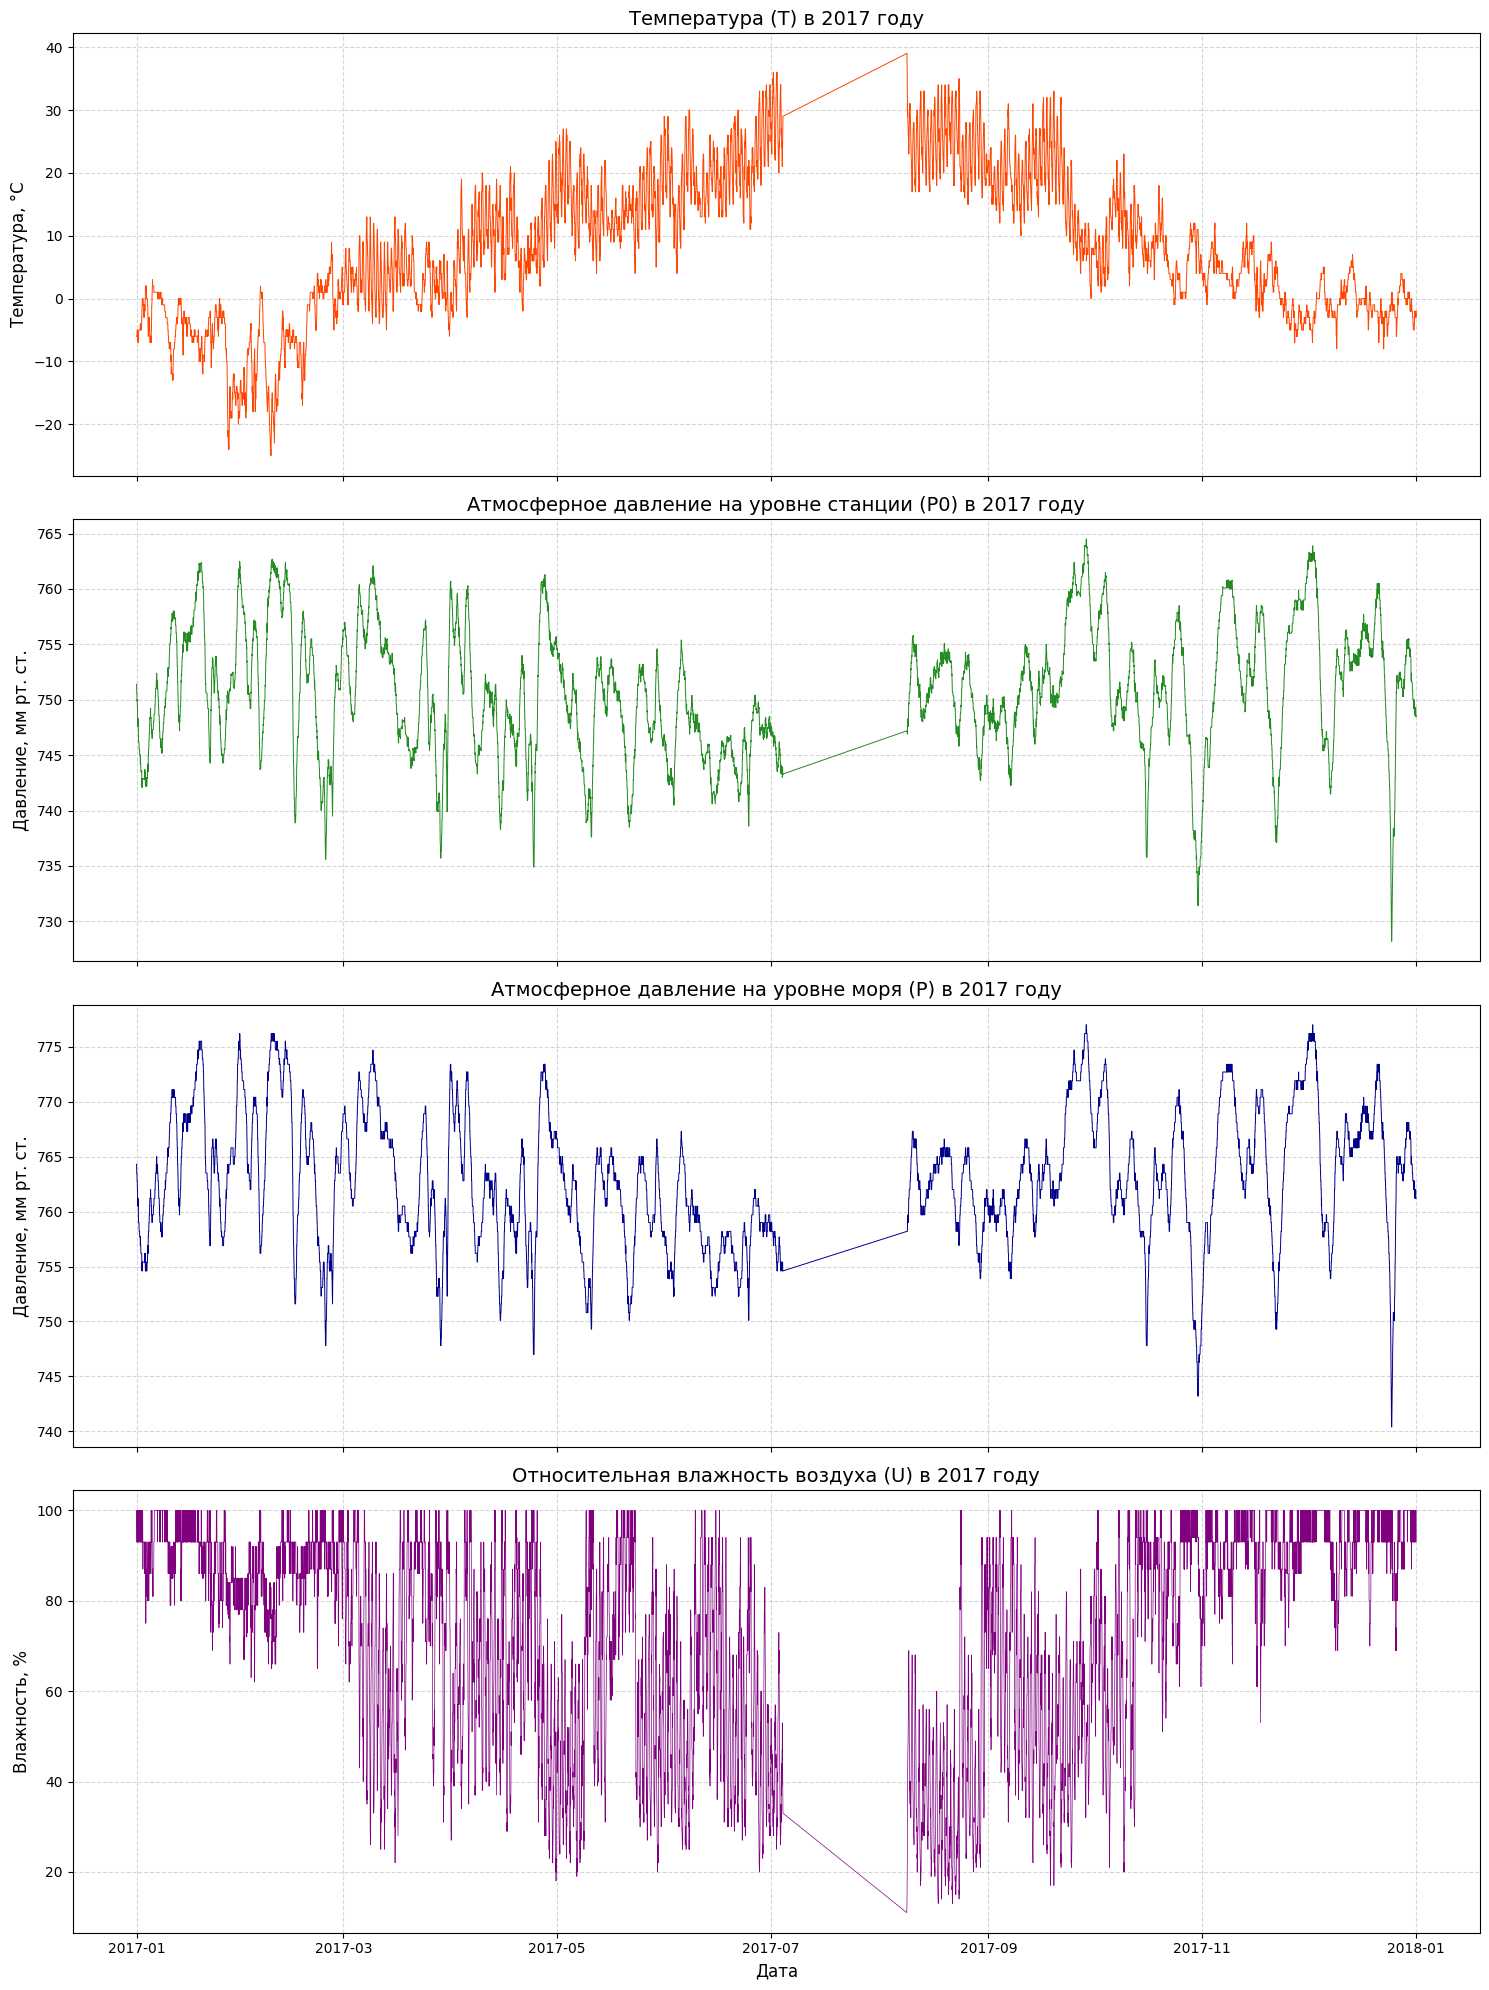

In [8]:
import matplotlib.pyplot as plt

data_2017 = data.loc['2017']

fig, axes = plt.subplots(4, 1, figsize=(15, 20), sharex=True)

# График температуры T
axes[0].plot(data_2017.index, data_2017['T'], color='orangered', linewidth=0.7)
axes[0].set_title('Температура (T) в 2017 году', fontsize=14)
axes[0].set_ylabel('Температура, °C', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# График давления P0
axes[1].plot(data_2017.index, data_2017['P0'], color='forestgreen', linewidth=0.7)
axes[1].set_title('Атмосферное давление на уровне станции (P0) в 2017 году', fontsize=14)
axes[1].set_ylabel('Давление, мм рт. ст.', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

# График давления P
axes[2].plot(data_2017.index, data_2017['P'], color='darkblue', linewidth=0.7)
axes[2].set_title('Атмосферное давление на уровне моря (P) в 2017 году', fontsize=14)
axes[2].set_ylabel('Давление, мм рт. ст.', fontsize=12)
axes[2].grid(True, linestyle='--', alpha=0.5)

# График влажности U
axes[3].plot(data_2017.index, data_2017['U'], color='purple', linewidth=0.5)
axes[3].set_title('Относительная влажность воздуха (U) в 2017 году', fontsize=14)
axes[3].set_xlabel('Дата', fontsize=12)
axes[3].set_ylabel('Влажность, %', fontsize=12)
axes[3].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Да похоже был период где данные отсутствовали и их синтетически заполнили

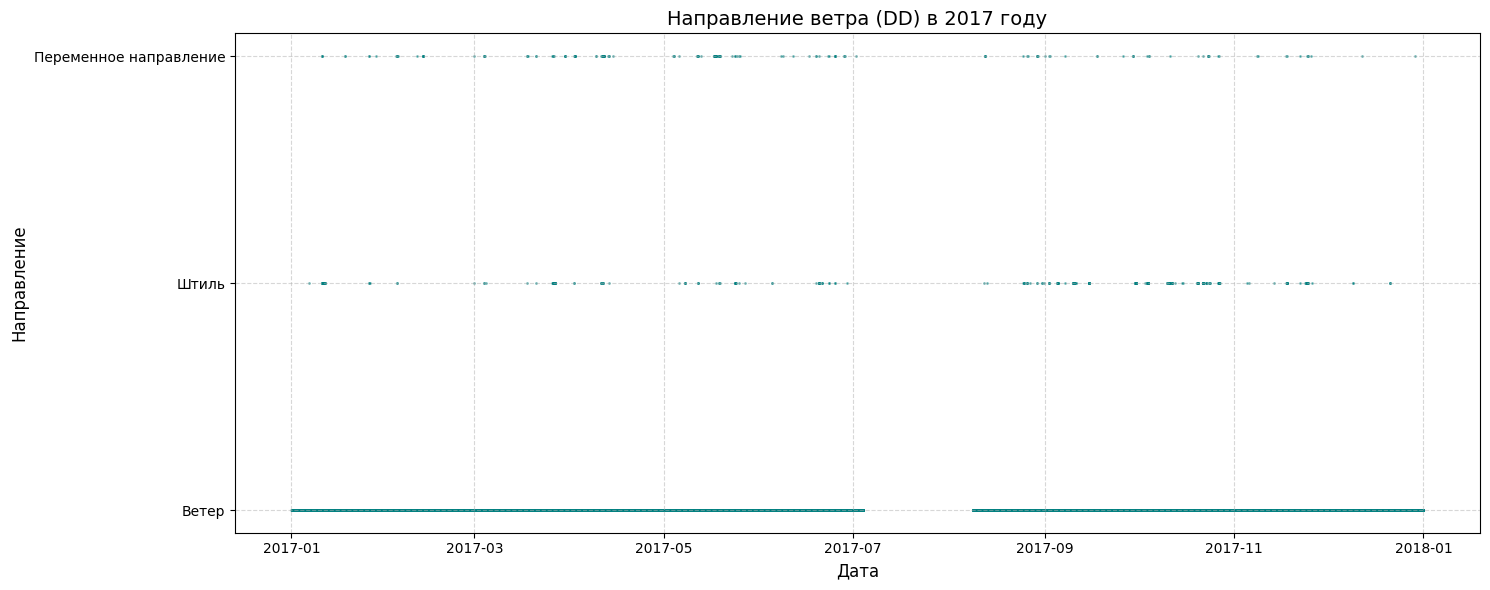

In [9]:
import matplotlib.pyplot as plt

data_2017 = data.loc['2017']

plt.figure(figsize=(15, 6))
plt.scatter(data_2017.index, data_2017['DD'], color='teal', s=1, alpha=0.5)
plt.title('Направление ветра (DD) в 2017 году', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Направление', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [10]:
# Проверка на наличие пропущенных значений в датасете
missing_values = data.isna().sum()
print("Количество пропусков по столбцам:")
print(missing_values)

Количество пропусков по столбцам:
T     6
P0    7
P     3
U     6
DD    7
dtype: int64


In [11]:
data = data.dropna()
data.isna().sum()

,0
T,0
P0,0
P,0
U,0
DD,0


Унитарно надо закодировать ветер, так как работать буду с нейронками, оставлю все столбцы

In [12]:
data = pd.get_dummies(data, columns=['DD'], dtype=int)
data.head()

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль
LocalTime,,,,,,,
2012-10-15 00:00:00,5.0,756.4,768.9,76.0,1,0,0
2012-10-15 01:00:00,6.0,756.5,768.9,81.0,1,0,0
2012-10-15 02:00:00,5.0,757.1,769.6,81.0,1,0,0
2012-10-15 03:00:00,6.0,757.2,769.6,76.0,1,0,0
2012-10-15 04:00:00,7.0,756.5,768.9,71.0,1,0,0


Далее создаю датасет для задачи с суточным предсказанием температуры. Первым делом агрегирую по суткам

In [13]:
# Ресемплируем данные к суточному шагу (Daily) и находим среднее значение
data_daily = data.resample('D').mean()

# Приводим индекс к формату даты (без времени)
data_daily.index = data_daily.index.date

data_daily.shape[0]

2923

In [14]:
data_daily

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль
2012-10-15,10.458333,756.720833,768.962500,58.166667,1.0,0.0,0.0
2012-10-16,14.333333,757.620833,769.700000,66.958333,1.0,0.0,0.0
2012-10-17,14.416667,757.879167,769.945833,53.708333,1.0,0.0,0.0
2012-10-18,13.791667,757.195833,769.279167,54.208333,1.0,0.0,0.0
2012-10-19,12.416667,760.083333,772.275000,57.083333,1.0,0.0,0.0
...,...,...,...,...,...,...,...
2020-10-11,11.744681,756.880851,769.051064,46.914894,1.0,0.0,0.0
2020-10-12,13.083333,755.218750,767.314583,56.770833,1.0,0.0,0.0
2020-10-13,15.688889,753.924444,765.888889,60.622222,1.0,0.0,0.0
2020-10-14,14.680851,752.568085,764.548936,45.361702,1.0,0.0,0.0


Нужно извлечь признаки из даты:
 - день недели (от 0 - понедельника до 6 - воскресенья)
 - месяц (от 1 до 12)
 - день в году (от 1 до 366)

In [15]:
# Преобразуем индекс обратно в формат DatetimeIndex для удобного извлечения календарных признаков
idx = pd.to_datetime(data_daily.index)

# Создаем новые признаки
data_daily['day_of_week'] = idx.dayofweek
data_daily['month'] = idx.month
data_daily['day_of_year'] = idx.dayofyear

# Отобразим обновленный датасет
data_daily

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,day_of_week,month,day_of_year
2012-10-15,10.458333,756.720833,768.962500,58.166667,1.0,0.0,0.0,0,10,289
2012-10-16,14.333333,757.620833,769.700000,66.958333,1.0,0.0,0.0,1,10,290
2012-10-17,14.416667,757.879167,769.945833,53.708333,1.0,0.0,0.0,2,10,291
2012-10-18,13.791667,757.195833,769.279167,54.208333,1.0,0.0,0.0,3,10,292
2012-10-19,12.416667,760.083333,772.275000,57.083333,1.0,0.0,0.0,4,10,293
...,...,...,...,...,...,...,...,...,...,...
2020-10-11,11.744681,756.880851,769.051064,46.914894,1.0,0.0,0.0,6,10,285
2020-10-12,13.083333,755.218750,767.314583,56.770833,1.0,0.0,0.0,0,10,286
2020-10-13,15.688889,753.924444,765.888889,60.622222,1.0,0.0,0.0,1,10,287
2020-10-14,14.680851,752.568085,764.548936,45.361702,1.0,0.0,0.0,2,10,288


К дням недели и месяцам применю циклическое кодирование

In [16]:
import numpy as np

# Циклическое кодирование для дня недели (период 7, значения от 0 до 6)
data_daily['day_of_week_sin'] = np.sin(2 * np.pi * data_daily['day_of_week'] / 7)
data_daily['day_of_week_cos'] = np.cos(2 * np.pi * data_daily['day_of_week'] / 7)

# Циклическое кодирование для месяца (период 12, значения от 1 до 12)
data_daily['month_sin'] = np.sin(2 * np.pi * data_daily['month'] / 12)
data_daily['month_cos'] = np.cos(2 * np.pi * data_daily['month'] / 12)

# Отобразим новые столбцы для проверки
display(data_daily[['day_of_week', 'day_of_week_sin', 'day_of_week_cos', 'month', 'month_sin', 'month_cos']].head())

,day_of_week,day_of_week_sin,day_of_week_cos,month,month_sin,month_cos
2012-10-15,0,0.000000,1.000000,10,-0.866025,0.5
2012-10-16,1,0.781831,0.623490,10,-0.866025,0.5
2012-10-17,2,0.974928,-0.222521,10,-0.866025,0.5
2012-10-18,3,0.433884,-0.900969,10,-0.866025,0.5
2012-10-19,4,-0.433884,-0.900969,10,-0.866025,0.5


Теперь надо создать лаги. Для суточной температуры lag_i будет означать температуру i дней назад. Тоесть для конкретного дня будет информация за неделю о температуре

In [17]:
# Создаем лаговые признаки для температуры T (от 1 до 7 дней)
for lag in range(1, 8):
    data_daily[f'lag_{lag}'] = data_daily['T'].shift(lag)

# Удаляем строки с образовавшимися пропусками (первые 7 дней)
data_daily = data_daily.dropna()

# Отобразим обновленный датасет с новыми признаками
data_daily.head(10)

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,day_of_week,month,day_of_year,...,day_of_week_cos,month_sin,month_cos,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7
2012-10-22,9.458333,753.962500,766.179167,51.625000,0.791667,0.0,0.208333,0,10,296,...,1.000000,-0.866025,0.5,9.833333,9.333333,12.416667,13.791667,14.416667,14.333333,10.458333
2012-10-23,5.791667,752.537500,764.904167,73.458333,1.000000,0.0,0.000000,1,10,297,...,0.623490,-0.866025,0.5,9.458333,9.833333,9.333333,12.416667,13.791667,14.416667,14.333333
2012-10-24,2.916667,750.170833,762.629167,81.333333,1.000000,0.0,0.000000,2,10,298,...,-0.222521,-0.866025,0.5,5.791667,9.458333,9.833333,9.333333,12.416667,13.791667,14.416667
2012-10-25,4.347826,747.939130,760.282609,88.695652,0.913043,0.0,0.086957,3,10,299,...,-0.900969,-0.866025,0.5,2.916667,5.791667,9.458333,9.833333,9.333333,12.416667,13.791667
2012-10-26,7.291667,743.937500,756.075000,76.583333,1.000000,0.0,0.000000,4,10,300,...,-0.900969,-0.866025,0.5,4.347826,2.916667,5.791667,9.458333,9.833333,9.333333,12.416667
2012-10-27,7.125000,749.337500,761.579167,68.041667,1.000000,0.0,0.000000,5,10,301,...,-0.222521,-0.866025,0.5,7.291667,4.347826,2.916667,5.791667,9.458333,9.833333,9.333333
2012-10-28,9.541667,752.537500,764.725000,64.833333,1.000000,0.0,0.000000,6,10,302,...,0.623490,-0.866025,0.5,7.125000,7.291667,4.347826,2.916667,5.791667,9.458333,9.833333
2012-10-29,12.500000,748.625000,760.625000,75.458333,1.000000,0.0,0.000000,0,10,303,...,1.000000,-0.866025,0.5,9.541667,7.125000,7.291667,4.347826,2.916667,5.791667,9.458333
2012-10-30,16.000000,746.429167,758.250000,74.208333,1.000000,0.0,0.000000,1,10,304,...,0.623490,-0.866025,0.5,12.500000,9.541667,7.125000,7.291667,4.347826,2.916667,5.791667
2012-10-31,12.458333,749.879167,761.908333,76.833333,1.000000,0.0,0.000000,2,10,305,...,-0.222521,-0.866025,0.5,16.000000,12.500000,9.541667,7.125000,7.291667,4.347826,2.916667


Всю полезную инфорацию из даты извлекли, теперь можно сделать обычный индекс

In [18]:
data_daily = data_daily.reset_index(drop=True)
data_daily

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,day_of_week,month,day_of_year,...,day_of_week_cos,month_sin,month_cos,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7
0,9.458333,753.962500,766.179167,51.625000,0.791667,0.0,0.208333,0,10,296,...,1.000000,-0.866025,0.5,9.833333,9.333333,12.416667,13.791667,14.416667,14.333333,10.458333
1,5.791667,752.537500,764.904167,73.458333,1.000000,0.0,0.000000,1,10,297,...,0.623490,-0.866025,0.5,9.458333,9.833333,9.333333,12.416667,13.791667,14.416667,14.333333
2,2.916667,750.170833,762.629167,81.333333,1.000000,0.0,0.000000,2,10,298,...,-0.222521,-0.866025,0.5,5.791667,9.458333,9.833333,9.333333,12.416667,13.791667,14.416667
3,4.347826,747.939130,760.282609,88.695652,0.913043,0.0,0.086957,3,10,299,...,-0.900969,-0.866025,0.5,2.916667,5.791667,9.458333,9.833333,9.333333,12.416667,13.791667
4,7.291667,743.937500,756.075000,76.583333,1.000000,0.0,0.000000,4,10,300,...,-0.900969,-0.866025,0.5,4.347826,2.916667,5.791667,9.458333,9.833333,9.333333,12.416667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2859,11.744681,756.880851,769.051064,46.914894,1.000000,0.0,0.000000,6,10,285,...,0.623490,-0.866025,0.5,11.829787,12.978261,11.191489,11.062500,11.270833,13.312500,13.829787
2860,13.083333,755.218750,767.314583,56.770833,1.000000,0.0,0.000000,0,10,286,...,1.000000,-0.866025,0.5,11.744681,11.829787,12.978261,11.191489,11.062500,11.270833,13.312500
2861,15.688889,753.924444,765.888889,60.622222,1.000000,0.0,0.000000,1,10,287,...,0.623490,-0.866025,0.5,13.083333,11.744681,11.829787,12.978261,11.191489,11.062500,11.270833
2862,14.680851,752.568085,764.548936,45.361702,1.000000,0.0,0.000000,2,10,288,...,-0.222521,-0.866025,0.5,15.688889,13.083333,11.744681,11.829787,12.978261,11.191489,11.062500


И забыл удалить старые признаки дня недели и месяца щас сделаю

In [19]:
data_daily = data_daily.drop(columns=['day_of_week', 'month'])
data_daily.describe(include='all')

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,day_of_year,day_of_week_sin,day_of_week_cos,month_sin,month_cos,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7
count,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2.864000e+03,2.864000e+03,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000
mean,9.223399,750.638389,762.838917,67.633881,0.972813,0.012526,0.014661,182.162011,0.001803,0.000218,9.206014e-03,5.570699e-03,9.223020,9.223117,9.222258,9.221751,9.218639,9.217735,9.218705
std,11.834338,5.846721,6.155080,21.279708,0.064928,0.032256,0.046411,106.149896,0.707255,0.707203,7.055633e-01,7.088116e-01,11.834349,11.834056,11.831672,11.828728,11.826164,11.825673,11.830098
min,-27.208333,728.802083,740.987500,18.925000,0.276596,0.000000,0.000000,1.000000,-0.974928,-0.900969,-1.000000e+00,-1.000000e+00,-27.208333,-27.208333,-27.208333,-27.208333,-27.208333,-27.208333,-27.208333
25%,-0.312500,746.727083,758.619167,48.916667,0.978723,0.000000,0.000000,90.000000,-0.781831,-0.900969,-5.000000e-01,-5.000000e-01,-0.312500,-0.312500,-0.312500,-0.312500,-0.312500,-0.312500,-0.312500
50%,8.841667,750.125291,762.206250,70.427083,1.000000,0.000000,0.000000,179.500000,0.000000,-0.222521,1.224647e-16,6.123234e-17,8.893750,8.946023,8.956439,8.958333,8.956439,8.956439,8.956439
75%,19.880208,754.113624,766.517619,86.661348,1.000000,0.000000,0.000000,274.000000,0.781831,0.623490,5.000000e-01,8.660254e-01,19.880208,19.880208,19.880208,19.880208,19.880208,19.880208,19.880208
max,32.791667,774.602083,788.779167,100.000000,1.000000,0.382979,0.608696,366.000000,0.974928,1.000000,1.000000e+00,1.000000e+00,32.791667,32.791667,32.791667,32.791667,32.791667,32.791667,34.866667


Проверить дубликаты

In [20]:
data_daily.duplicated().sum()

np.int64(0)

Отлично, нет дубликатов

Разделяю датасет на тренировочный, валидационный и тестовый

In [29]:
n = len(data_daily)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

train_daily = data_daily.iloc[:train_end]
val_daily = data_daily.iloc[train_end:val_end]
test_daily = data_daily.iloc[val_end:]

Привожу признаки и таргет к одному масштабу

In [30]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = ['P0', 'P', 'U', 'day_of_year'] + [f'lag_{i}' for i in range(1, 8)]
target_col = 'T'

scaler_daily_X = StandardScaler()
scaler_daily_y = StandardScaler()

train_daily[cols_to_scale] = scaler_daily_X.fit_transform(train_daily[cols_to_scale])
train_daily[[target_col]] = scaler_daily_y.fit_transform(train_daily[[target_col]])

val_daily[cols_to_scale] = scaler_daily_X.transform(val_daily[cols_to_scale])
val_daily[[target_col]] = scaler_daily_y.transform(val_daily[[target_col]])

test_daily[cols_to_scale] = scaler_daily_X.transform(test_daily[cols_to_scale])
test_daily[[target_col]] = scaler_daily_y.transform(test_daily[[target_col]])

/tmp/ipykernel_5213/3673467522.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_daily[cols_to_scale] = scaler_daily_X.fit_transform(train_daily[cols_to_scale])
/tmp/ipykernel_5213/3673467522.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_daily[[target_col]] = scaler_daily_y.fit_transform(train_daily[[target_col]])
/tmp/ipykernel_5213/3673467522.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = val

В будуем для работы с нейросетями понадобятся обученные скейлеры, сохраню и их тоже

In [ ]:
import joblib

joblib.dump(scaler_daily_X, 'scaler_daily_X.pkl')
joblib.dump(scaler_daily_y, 'scaler_daily_y.pkl')

train_daily.to_csv('train_daily.csv', index=False)
val_daily.to_csv('val_daily.csv', index=False)
test_daily.to_csv('test_daily.csv', index=False)

In [ ]:
data

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль
LocalTime,,,,,,,
2012-10-15 00:00:00,5.0,756.4,768.9,76.0,1,0,0
2012-10-15 01:00:00,6.0,756.5,768.9,81.0,1,0,0
2012-10-15 02:00:00,5.0,757.1,769.6,81.0,1,0,0
2012-10-15 03:00:00,6.0,757.2,769.6,76.0,1,0,0
2012-10-15 04:00:00,7.0,756.5,768.9,71.0,1,0,0
...,...,...,...,...,...,...,...
2020-10-15 20:00:00,13.0,752.3,764.3,88.0,1,0,0
2020-10-15 20:30:00,13.0,752.3,764.3,82.0,1,0,0
2020-10-15 21:00:00,13.0,752.3,764.3,82.0,1,0,0


Первый датасет обработан, теперь надо для предсказания средней погоды за неделю. Сагрегирую по неделям

In [21]:
data_weekly = data.resample('W').mean()
data_weekly.shape[0]

418

Маловато конечно строк, ну посмотрю как поведут себя нейронки

In [22]:
import numpy as np

# Извлекаем номер недели в году
data_weekly['week_of_year'] = data_weekly.index.isocalendar().week.astype(int)

# Применяем циклическое кодирование для номера недели (период ~52 недели)
data_weekly['week_sin'] = np.sin(2 * np.pi * data_weekly['week_of_year'] / 52)
data_weekly['week_cos'] = np.cos(2 * np.pi * data_weekly['week_of_year'] / 52)

# Отобразим новые признаки
data_weekly[['week_of_year', 'week_sin', 'week_cos']].head(10)

,week_of_year,week_sin,week_cos
LocalTime,,,
2012-10-21,42,-0.935016,0.354605
2012-10-28,43,-0.885456,0.464723
2012-11-04,44,-0.822984,0.568065
2012-11-11,45,-0.748511,0.663123
2012-11-18,46,-0.663123,0.748511
2012-11-25,47,-0.568065,0.822984
2012-12-02,48,-0.464723,0.885456
2012-12-09,49,-0.354605,0.935016
2012-12-16,50,-0.239316,0.970942


In [23]:
data_weekly = data_weekly.drop(columns=['week_of_year'])
data_weekly

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,week_sin,week_cos
LocalTime,,,,,,,,,
2012-10-21,12.083333,758.505357,770.686310,57.202381,0.970238,0.005952,0.023810,-0.935016,3.546049e-01
2012-10-28,6.652695,750.073054,762.351497,71.982036,0.958084,0.000000,0.041916,-0.885456,4.647232e-01
2012-11-04,7.470238,752.904762,765.200000,79.101190,0.952381,0.011905,0.035714,-0.822984,5.680647e-01
2012-11-11,6.095808,751.414970,763.740120,84.197605,0.976048,0.017964,0.005988,-0.748511,6.631227e-01
2012-11-18,1.452381,756.627976,769.250595,80.125000,0.946429,0.005952,0.047619,-0.663123,7.485107e-01
...,...,...,...,...,...,...,...,...,...
2020-09-20,14.785933,750.031193,761.962997,49.036697,0.975535,0.012232,0.012232,-0.992709,-1.205367e-01
2020-09-27,15.374622,753.884894,765.854683,41.117825,0.987915,0.006042,0.006042,-1.000000,-1.836970e-16
2020-10-04,14.919162,757.774850,769.823353,37.002994,0.997006,0.002994,0.000000,-0.992709,1.205367e-01


Тут с лагами поступлю чучуть по-другому. Создам 12 лагов для окна о погоде за 3 месяца и создам лаги для информации о том какая была температура на этой неделе но год назад

In [24]:
# Создаем краткосрочные лаги (от 1 до 12 недель)
for lag in range(1, 13):
    data_weekly[f'lag_{lag}'] = data_weekly['T'].shift(lag)

# Создаем прошлогодние сезонные лаги (51, 52, 53 недели)
for lag in [51, 52, 53]:
    data_weekly[f'lag_{lag}'] = data_weekly['T'].shift(lag)

# Удаляем строки с пропусками
data_weekly = data_weekly.dropna()

# Отобразим результат
display(data_weekly.head())
print(f"\nРазмер недельного датасета после добавления лагов и удаления пропусков: {data_weekly.shape[0]} строк")

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,week_sin,week_cos,lag_1,...,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_51,lag_52,lag_53
LocalTime,,,,,,,,,,,,,,,,,,,,,
2013-10-27,5.273810,755.932738,768.373214,78.880952,0.952381,0.017857,0.029762,-0.885456,0.464723,9.601190,...,14.239521,16.369048,20.269461,22.674699,26.071429,22.604790,20.491018,7.470238,6.652695,12.083333
2013-11-03,8.186747,753.487349,765.759639,89.126506,0.993976,0.006024,0.000000,-0.822984,0.568065,5.273810,...,15.559524,14.239521,16.369048,20.269461,22.674699,26.071429,22.604790,6.095808,7.470238,6.652695
2013-11-10,8.404762,752.695833,764.946429,86.369048,1.000000,0.000000,0.000000,-0.748511,0.663123,8.186747,...,9.220238,15.559524,14.239521,16.369048,20.269461,22.674699,26.071429,1.452381,6.095808,7.470238
2013-11-17,5.357143,751.807143,764.176786,85.636905,1.000000,0.000000,0.000000,-0.663123,0.748511,8.404762,...,4.625000,9.220238,15.559524,14.239521,16.369048,20.269461,22.674699,-1.351190,1.452381,6.095808
2013-11-24,1.500000,757.335714,769.973810,72.279762,0.994048,0.005952,0.000000,-0.568065,0.822984,5.357143,...,10.023952,4.625000,9.220238,15.559524,14.239521,16.369048,20.269461,4.107784,-1.351190,1.452381



Размер недельного датасета после добавления лагов и удаления пропусков: 343 строк


In [25]:
data_weekly = data_weekly.reset_index(drop=True)
data_weekly

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,week_sin,week_cos,lag_1,...,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_51,lag_52,lag_53
0,5.273810,755.932738,768.373214,78.880952,0.952381,0.017857,0.029762,-0.885456,4.647232e-01,9.601190,...,14.239521,16.369048,20.269461,22.674699,26.071429,22.604790,20.491018,7.470238,6.652695,12.083333
1,8.186747,753.487349,765.759639,89.126506,0.993976,0.006024,0.000000,-0.822984,5.680647e-01,5.273810,...,15.559524,14.239521,16.369048,20.269461,22.674699,26.071429,22.604790,6.095808,7.470238,6.652695
2,8.404762,752.695833,764.946429,86.369048,1.000000,0.000000,0.000000,-0.748511,6.631227e-01,8.186747,...,9.220238,15.559524,14.239521,16.369048,20.269461,22.674699,26.071429,1.452381,6.095808,7.470238
3,5.357143,751.807143,764.176786,85.636905,1.000000,0.000000,0.000000,-0.663123,7.485107e-01,8.404762,...,4.625000,9.220238,15.559524,14.239521,16.369048,20.269461,22.674699,-1.351190,1.452381,6.095808
4,1.500000,757.335714,769.973810,72.279762,0.994048,0.005952,0.000000,-0.568065,8.229839e-01,5.357143,...,10.023952,4.625000,9.220238,15.559524,14.239521,16.369048,20.269461,4.107784,-1.351190,1.452381
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
338,14.785933,750.031193,761.962997,49.036697,0.975535,0.012232,0.012232,-0.992709,-1.205367e-01,19.330247,...,24.000000,25.213855,24.176829,25.798193,29.391566,25.735736,23.000000,9.591592,13.068452,18.901493
339,15.374622,753.884894,765.854683,41.117825,0.987915,0.006042,0.006042,-1.000000,-1.836970e-16,14.785933,...,19.516923,24.000000,25.213855,24.176829,25.798193,29.391566,25.735736,15.141141,9.591592,13.068452
340,14.919162,757.774850,769.823353,37.002994,0.997006,0.002994,0.000000,-0.992709,1.205367e-01,15.374622,...,21.599398,19.516923,24.000000,25.213855,24.176829,25.798193,29.391566,7.312139,15.141141,9.591592
341,11.909366,760.476133,772.696979,45.126888,1.000000,0.000000,0.000000,-0.970942,2.393157e-01,14.919162,...,21.722892,21.599398,19.516923,24.000000,25.213855,24.176829,25.798193,11.129921,7.312139,15.141141


In [28]:
data_weekly.duplicated().sum()

np.int64(0)

In [26]:
n = len(data_weekly)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

train_weekly = data_weekly.iloc[:train_end]
val_weekly = data_weekly.iloc[train_end:val_end]
test_weekly = data_weekly.iloc[val_end:]

In [31]:
cols_to_scale = ['P0', 'P', 'U'] + [f'lag_{i}' for i in range(1, 13)] + [f'lag_{i}' for i in range(51, 54)]
target_col = 'T'

scaler_weekly_X = StandardScaler()
scaler_weekly_y = StandardScaler()

train_weekly[cols_to_scale] = scaler_weekly_X.fit_transform(train_weekly[cols_to_scale])
train_weekly[[target_col]] = scaler_weekly_y.fit_transform(train_weekly[[target_col]])

val_weekly[cols_to_scale] = scaler_weekly_X.transform(val_weekly[cols_to_scale])
val_weekly[[target_col]] = scaler_weekly_y.transform(val_weekly[[target_col]])

test_weekly[cols_to_scale] = scaler_weekly_X.transform(test_weekly[cols_to_scale])
test_weekly[[target_col]] = scaler_weekly_y.transform(test_weekly[[target_col]])

/tmp/ipykernel_5213/3164701324.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_weekly[cols_to_scale] = scaler_weekly_X.fit_transform(train_weekly[cols_to_scale])
/tmp/ipykernel_5213/3164701324.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_weekly[[target_col]] = scaler_weekly_y.fit_transform(train_weekly[[target_col]])
/tmp/ipykernel_5213/3164701324.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] 

In [ ]:
train_weekly

,T,P0,P,U,DD_Ветер,DD_Переменное направление,DD_Штиль,week_sin,week_cos,lag_1,...,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_51,lag_52,lag_53
0,-0.258775,1.144028,1.108149,0.525423,0.952381,0.017857,0.029762,-0.885456,4.647232e-01,0.123744,...,0.536446,0.714327,1.039908,1.239919,1.513728,1.207338,1.011836,-0.078626,-0.140762,0.340454
1,-0.008939,0.585193,0.551162,1.050317,0.993976,0.006024,0.000000,-0.822984,5.680647e-01,-0.250615,...,0.650677,0.530887,0.705556,1.034254,1.225184,1.500429,1.189430,-0.198069,-0.069319,-0.135593
2,0.009760,0.404311,0.377857,0.909048,1.000000,0.000000,0.000000,-0.748511,6.631227e-01,0.001382,...,0.102084,0.644594,0.523009,0.700743,1.020865,1.213249,1.480689,-0.601597,-0.189428,-0.063928
3,-0.251628,0.201222,0.213836,0.871540,1.000000,0.000000,0.000000,-0.663123,7.485107e-01,0.020242,...,-0.295581,0.098520,0.636162,0.518653,0.689534,1.009895,1.195304,-0.845237,-0.595207,-0.184409
4,-0.582447,1.464644,1.449257,0.187235,0.994048,0.005952,0.000000,-0.568065,8.229839e-01,-0.243406,...,0.171636,-0.297320,0.092745,0.631523,0.508636,0.680131,0.993221,-0.370834,-0.840205,-0.591450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,0.386781,0.211356,0.154088,-0.118629,0.916667,0.002976,0.080357,-1.000000,-1.836970e-16,0.754772,...,1.333971,1.299926,1.467870,1.509195,1.287454,1.614735,1.486507,0.186524,0.020670,1.078780
236,0.250216,0.553669,0.493483,-0.133571,1.000000,0.000000,0.000000,-0.992709,1.205367e-01,0.400523,...,1.091174,1.324751,1.288305,1.461143,1.492699,1.275224,1.594281,0.223724,0.197310,0.026341
237,0.255576,1.343444,1.240330,-0.014489,0.898810,0.026786,0.074405,-0.970942,2.393157e-01,0.262777,...,1.370771,1.083068,1.313009,1.282028,1.444961,1.479500,1.256892,-0.001810,0.234718,0.203531
238,0.377434,0.946473,0.851103,0.319541,0.916168,0.011976,0.071856,-0.935016,3.546049e-01,0.268184,...,1.140143,1.361382,1.072503,1.306670,1.267017,1.431987,1.459891,-0.341922,0.007926,0.241055


Кстати из-за разных скейлеров для признаков и для таргета фактическая температура и температура в лагах слегка отличается, но для нейросети в этом проблем не будет

In [ ]:
joblib.dump(scaler_weekly_X, 'scaler_weekly_X.pkl')
joblib.dump(scaler_weekly_y, 'scaler_weekly_y.pkl')

train_weekly.to_csv('train_weekly.csv', index=False)
val_weekly.to_csv('val_weekly.csv', index=False)
test_weekly.to_csv('test_weekly.csv', index=False)